# German Credit Risk: Exploration, Drivers, and Bayesian Optimization

This notebook analyzes the Kaggle **Weka German Credit** dataset. Each row is an applicant; `class` labels credit risk as `good` or `bad` (300 bad / 700 good). The 20 predictors include 13 categorical and 7 numeric fields. This is a small, historical teaching dataset, not a production underwriting model. Its `bad` label is treated as the positive class throughout.

The accompanying Chapter 2 material emphasizes binary default outcomes, GLM/logistic baselines, machine-learning challengers, and validation. Accordingly, this notebook uses a logistic-regression baseline and a random-forest challenger, with preprocessing fitted inside pipelines.

Compared with fixed-hyperparameter baselines, this version **tunes** both models with a lightweight **Bayesian optimization** loop (Gaussian-process surrogate + expected improvement). Validation uses stratified 5-fold CV on the training split and a held-out test set.

In [1]:
from pathlib import Path
import io
import zipfile
import textwrap
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm, ttest_rel

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
    roc_auc_score, average_precision_score, brier_score_loss,
    balanced_accuracy_score,
)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Imports OK")

Imports OK


## Load and validate data
The CSV is included alongside this notebook. For a fresh run without the local file, it can be downloaded from the public Kaggle dataset endpoint. Kaggle may revise the archive, so shape and target checks below act as safeguards.

In [2]:
DATA_PATH = Path("credit-g.csv")

def load_data():
    if not DATA_PATH.exists():
        import requests
        url = "https://www.kaggle.com/api/v1/datasets/download/btolar1/weka-german-credit"
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
            csv_name = next(name for name in archive.namelist() if name.lower().endswith(".csv"))
            DATA_PATH.write_bytes(archive.read(csv_name))
    data = pd.read_csv(DATA_PATH)
    data.columns = data.columns.str.strip()
    if data.shape[0] != 1000 or "class" not in data.columns:
        raise ValueError(f"Unexpected dataset shape or missing target: {data.shape}")
    if set(data["class"].unique()) != {"good", "bad"}:
        raise ValueError("Expected target labels 'good' and 'bad'.")
    return data

df = load_data()
df.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [3]:
print("Shape:", df.shape)
print("Target counts:\n", df["class"].value_counts())
assert df.shape[0] == 1000 and "class" in df.columns
assert set(df["class"].unique()) == {"good", "bad"}
df.info()

Shape: (1000, 21)
Target counts:
 class
good    700
bad     300
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   checking_status         1000 non-null   object
 1   duration                1000 non-null   int64 
 2   credit_history          1000 non-null   object
 3   purpose                 1000 non-null   object
 4   credit_amount           1000 non-null   int64 
 5   savings_status          1000 non-null   object
 6   employment              1000 non-null   object
 7   installment_commitment  1000 non-null   int64 
 8   personal_status         1000 non-null   object
 9   other_parties           1000 non-null   object
 10  residence_since         1000 non-null   int64 
 11  property_magnitude      1000 non-null   object
 12  age                     1000 non-null   int64 
 13  other_payment_plans

## Data preparation and exploration
Check duplicate rows, missingness, type balance, class imbalance, and summary statistics. Numeric codes such as `installment_commitment` are retained as numeric ordinal values because they represent ordered categories.

In [4]:
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Missing values (largest first):\n", df.isna().sum().sort_values(ascending=False).head(10))
print("\nUnique values per field:\n", df.nunique().sort_values())
print("\nNumeric summary:")
print(df.describe().T.to_string())

Exact duplicate rows: 0
Missing values (largest first):
 checking_status           0
duration                  0
credit_history            0
purpose                   0
credit_amount             0
savings_status            0
employment                0
installment_commitment    0
personal_status           0
other_parties             0
dtype: int64

Unique values per field:
 class                       2
foreign_worker              2
own_telephone               2
num_dependents              2
other_payment_plans         3
housing                     3
other_parties               3
checking_status             4
existing_credits            4
installment_commitment      4
residence_since             4
job                         4
personal_status             4
property_magnitude          4
credit_history              5
savings_status              5
employment                  5
purpose                    10
duration                   33
age                        53
credit_amount          

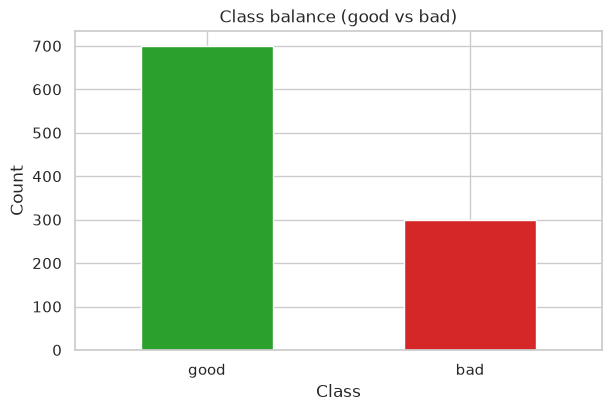

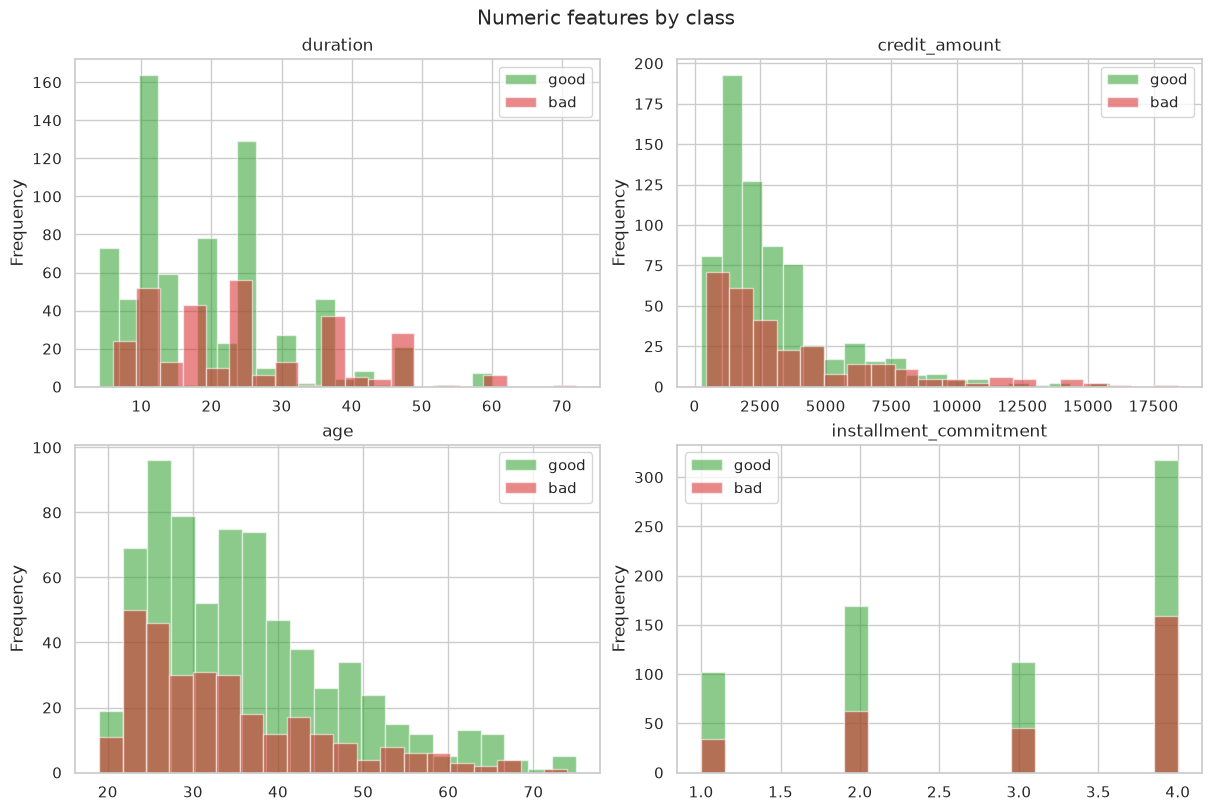

In [5]:
num_cols_preview = ["duration", "credit_amount", "age", "installment_commitment"]

fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
df["class"].value_counts().reindex(["good", "bad"]).plot(
    kind="bar", ax=ax, color=["#2ca02c", "#d62728"], rot=0
)
ax.set_title("Class balance (good vs bad)")
ax.set_ylabel("Count")
ax.set_xlabel("Class")

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, col in zip(axes.ravel(), num_cols_preview):
    for label, color in [("good", "#2ca02c"), ("bad", "#d62728")]:
        df.loc[df["class"] == label, col].plot.hist(ax=ax, alpha=0.55, bins=20, color=color, label=label)
    ax.set_title(col)
    ax.legend()
plt.suptitle("Numeric features by class")
plt.show()


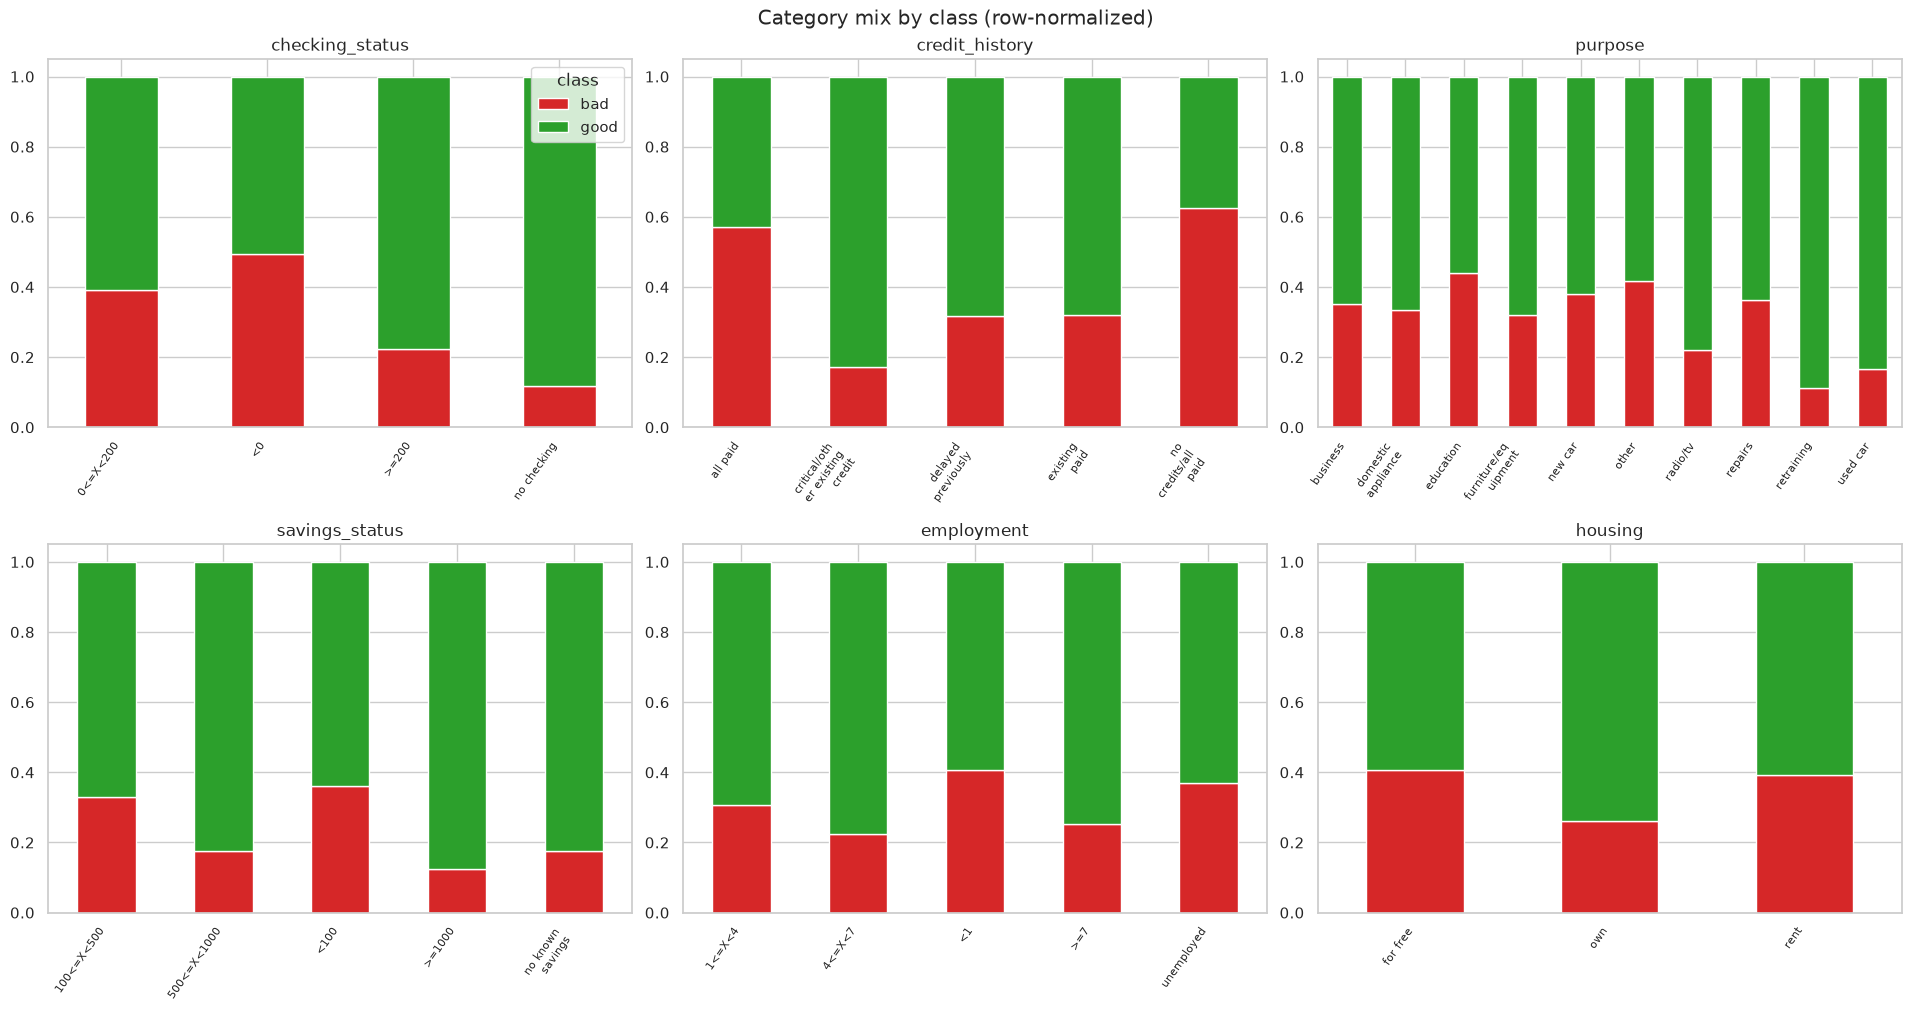

In [6]:
import textwrap
cat_preview = ["checking_status", "credit_history", "purpose", "savings_status", "employment", "housing"]
fig, axes = plt.subplots(2, 3, figsize=(19, 10), constrained_layout=True)
for ax, col in zip(axes.ravel(), cat_preview):
    ct = pd.crosstab(df[col], df["class"], normalize="index")
    ct.plot(kind="bar", stacked=True, ax=ax, color=["#d62728", "#2ca02c"], legend=False)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelrotation=55, labelsize=8)
    ax.set_xticklabels(
        [textwrap.fill(tick.get_text(), width=12) for tick in ax.get_xticklabels()],
        rotation=55, ha="right", fontsize=8
    )
axes[0, 0].legend(title="class", loc="best")
plt.suptitle("Category mix by class (row-normalized)")
plt.show()

## Train/test split and preprocessing
Stratified 80/20 split. Numeric columns are median-imputed and standardized; categorical columns are mode-imputed and one-hot encoded. All transforms live inside a `ColumnTransformer` so they are fitted only on training folds.

Train: (800, 20) Test: (200, 20)
Positive rate train: 0.3 test: 0.3
Numeric: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']
Categorical: ['checking_status', 'credit_history', 'purpose', 'savings_status', 'employment', 'personal_status', 'other_parties', 'property_magnitude', 'other_payment_plans', 'housing', 'job', 'own_telephone', 'foreign_worker']


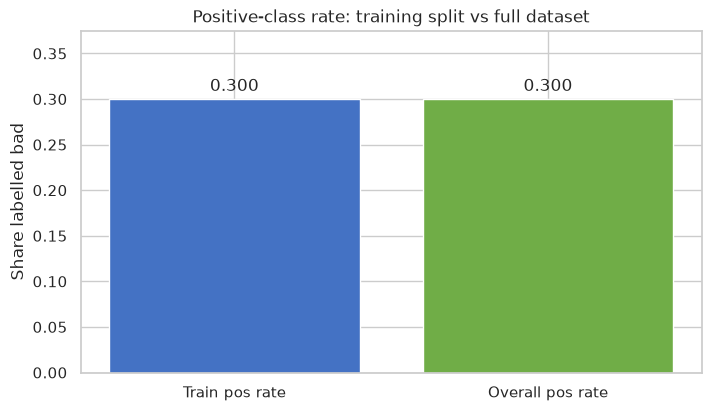

In [7]:
X = df.drop(columns="class")
y = (df["class"] == "bad").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = X_train.select_dtypes(exclude="object").columns.tolist()

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
prep = ColumnTransformer([
    ("numeric", num_pipe, num_cols),
    ("categorical", cat_pipe, cat_cols),
])

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Positive rate train:", round(y_train.mean(), 3), "test:", round(y_test.mean(), 3))
print("Numeric:", num_cols)
print("Categorical:", cat_cols)
fig, ax = plt.subplots(figsize=(7, 4), constrained_layout=True)
rate_labels = ["Train pos rate", "Overall pos rate"]
rate_values = [float(y_train.mean()), float(y.mean())]
bars = ax.bar(rate_labels, rate_values, color=["#4472C4", "#70AD47"])
ax.bar_label(bars, fmt="%.3f", padding=3)
ax.set_ylim(0, max(rate_values) * 1.25)
ax.set_ylabel("Share labelled bad")
ax.set_title("Positive-class rate: training split vs full dataset")
plt.show()


## Bayesian hyperparameter optimization
For each model family we run a small BO loop:

1. **Warm-start** with a few random configurations.
2. Fit a **Gaussian process** on encoded hyperparameters vs. CV ROC-AUC.
3. Propose the next point by maximizing **expected improvement**.
4. Evaluate with stratified 5-fold CV (preprocessing inside the pipeline).

Search spaces cover regularization / class weight for logistic regression and tree depth, leaf size, feature subsample, and class weight for the forest. Trial budget is intentionally modest (5 initial + 10 BO steps) so the notebook remains runnable on modest hardware.

In [8]:
def make_pipeline(name, params, prep):
    if name == "Logistic regression":
        model = LogisticRegression(
            max_iter=3000,
            solver="lbfgs",
            random_state=RANDOM_STATE,
            **params,
        )
    else:
        model = RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )
    return Pipeline([("prep", prep), ("model", model)])


def sample_params(space, rng):
    params = {}
    for key, spec in space.items():
        if spec[0] == "cat":
            params[key] = spec[1][rng.integers(len(spec[1]))]
        elif spec[0] == "log_float":
            params[key] = float(np.exp(rng.uniform(np.log(spec[1]), np.log(spec[2]))))
        else:
            params[key] = int(rng.integers(spec[1], spec[2] + 1))
    return params


def encode_params(params, space):
    values = []
    for key, spec in space.items():
        value = params[key]
        if spec[0] == "cat":
            values.extend(float(value == choice) for choice in spec[1])
        elif spec[0] == "log_float":
            values.append(
                (np.log(value) - np.log(spec[1])) /
                (np.log(spec[2]) - np.log(spec[1]))
            )
        else:
            values.append((value - spec[1]) / (spec[2] - spec[1]))
    return np.asarray(values, dtype=float)


def bayesian_optimize(name, space, prep, X_train, y_train, cv,
                      n_initial=5, n_iter=10, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    params_seen, scores, points = [], [], []
    history = []
    for trial in range(n_initial + n_iter):
        if trial < n_initial:
            params = sample_params(space, rng)
        else:
            gp = GaussianProcessRegressor(
                kernel=ConstantKernel(1.0) * Matern(nu=2.5) + WhiteKernel(),
                normalize_y=True,
                random_state=seed + trial,
            )
            gp.fit(np.vstack(points), np.asarray(scores))
            candidates = [sample_params(space, rng) for _ in range(256)]
            candidate_points = np.vstack([encode_params(p, space) for p in candidates])
            mean, std = gp.predict(candidate_points, return_std=True)
            improvement = mean - max(scores) - 0.01
            z = np.divide(improvement, std, out=np.zeros_like(std), where=std > 1e-12)
            expected_improvement = improvement * norm.cdf(z) + std * norm.pdf(z)
            expected_improvement[std <= 1e-12] = 0.0
            for i, candidate in enumerate(candidates):
                if candidate in params_seen:
                    expected_improvement[i] = -np.inf
            params = candidates[int(np.argmax(expected_improvement))]
        score = cross_val_score(
            make_pipeline(name, params, prep),
            X_train,
            y_train,
            cv=cv,
            scoring="roc_auc",
            n_jobs=1,
        ).mean()
        params_seen.append(params)
        scores.append(float(score))
        points.append(encode_params(params, space))
        history.append({"trial": trial + 1, "score": float(score), "params": dict(params)})
        print(f"{name}: trial {trial + 1}, CV ROC-AUC={score:.4f}, params={params}")
    best_idx = int(np.argmax(scores))
    return params_seen[best_idx], scores[best_idx], history

In [9]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_spaces = {
    "Logistic regression": {
        "C": ("log_float", 0.01, 100.0),
        "class_weight": ("cat", [None, "balanced"]),
    },
    "Random forest": {
        "n_estimators": ("int", 200, 600),
        "max_depth": ("cat", [None, 5, 10, 15, 20]),
        "min_samples_split": ("int", 2, 20),
        "min_samples_leaf": ("int", 1, 10),
        "max_features": ("cat", ["sqrt", "log2", 0.5, 1.0]),
        "class_weight": ("cat", [None, "balanced", "balanced_subsample"]),
    },
}

results = {}
histories = {}
for i, (name, space) in enumerate(search_spaces.items()):
    best_params, best_score, hist = bayesian_optimize(
        name, space, prep, X_train, y_train, cv, seed=RANDOM_STATE + 100 * i
    )
    results[name] = (best_params, best_score)
    histories[name] = hist

summary = pd.DataFrame([
    {"Model": name, "CV ROC-AUC": score, "Best parameters": params}
    for name, (params, score) in results.items()
]).sort_values("CV ROC-AUC", ascending=False)
print("\nBayesian optimization results:")
print(summary.to_string(index=False))
summary

Logistic regression: trial 1, CV ROC-AUC=0.7592, params={'C': 12.468786659075652, 'class_weight': 'balanced'}
Logistic regression: trial 2, CV ROC-AUC=0.7580, params={'C': 27.188902645221685, 'class_weight': None}


Logistic regression: trial 3, CV ROC-AUC=0.7619, params={'C': 6.158459876169442, 'class_weight': None}
Logistic regression: trial 4, CV ROC-AUC=0.7565, params={'C': 79.88944545350398, 'class_weight': None}


Logistic regression: trial 5, CV ROC-AUC=0.7595, params={'C': 11.080485964481518, 'class_weight': 'balanced'}
Logistic regression: trial 6, CV ROC-AUC=0.7701, params={'C': 1.0600338321712948, 'class_weight': None}


Logistic regression: trial 7, CV ROC-AUC=0.7838, params={'C': 0.04185682249187424, 'class_weight': None}
Logistic regression: trial 8, CV ROC-AUC=0.7767, params={'C': 0.010376010891177257, 'class_weight': 'balanced'}


Logistic regression: trial 9, CV ROC-AUC=0.7751, params={'C': 0.01009880206299714, 'class_weight': None}
Logistic regression: trial 10, CV ROC-AUC=0.7800, params={'C': 0.13683753497819812, 'class_weight': 'balanced'}


Logistic regression: trial 11, CV ROC-AUC=0.7812, params={'C': 0.14765432538919776, 'class_weight': None}
Logistic regression: trial 12, CV ROC-AUC=0.7709, params={'C': 0.6478592484099266, 'class_weight': 'balanced'}


... (14 outputs left out)

Random forest: trial 13, CV ROC-AUC=0.7959, params={'n_estimators': 433, 'max_depth': 15, 'min_samples_split': 11, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}


Random forest: trial 14, CV ROC-AUC=0.7942, params={'n_estimators': 335, 'max_depth': 20, 'min_samples_split': 5, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'class_weight': None}


Random forest: trial 15, CV ROC-AUC=0.7920, params={'n_estimators': 276, 'max_depth': None, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}

Bayesian optimization results:
              Model  CV ROC-AUC                                                                                                                                     Best parameters
      Random forest    0.796987 {'n_estimators': 348, 'max_depth': 20, 'min_samples_split': 6, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}
Logistic regression    0.783817                                                                                                    {'C': 0.04185682249187424, 'class_weight': None}


,Model,CV ROC-AUC,Best parameters
1,Random forest,0.796987,"{'n_estimators': 348, 'max_depth': 20, 'min_sa..."
0,Logistic regression,0.783817,"{'C': 0.04185682249187424, 'class_weight': None}"


## Optimization trajectory
Plotting CV ROC-AUC by trial for each model family shows whether BO improved on the random warm-start and how stable later proposals were.

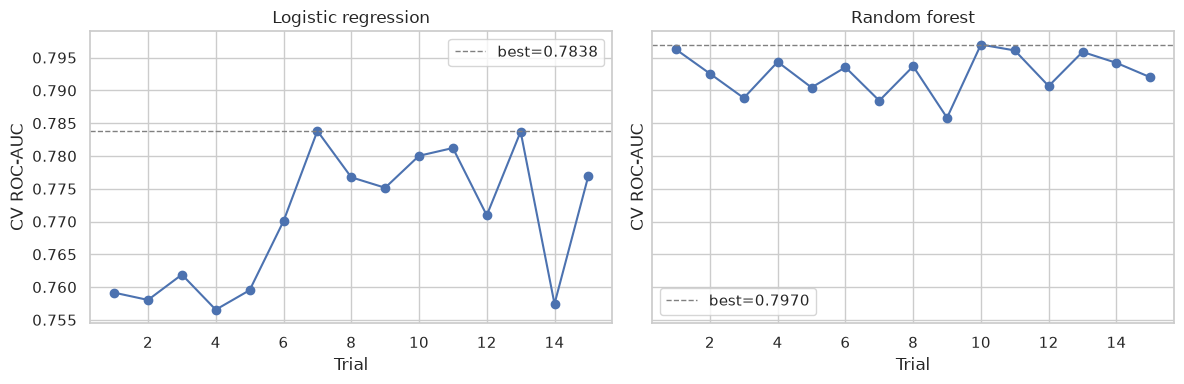

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for axi, (name, hist) in zip(ax, histories.items()):
    trials = [h["trial"] for h in hist]
    scores = [h["score"] for h in hist]
    axi.plot(trials, scores, marker="o")
    axi.axhline(max(scores), color="gray", linestyle="--", linewidth=1, label=f"best={max(scores):.4f}")
    axi.set_title(name)
    axi.set_xlabel("Trial")
    axi.set_ylabel("CV ROC-AUC")
    axi.legend()
plt.tight_layout()
plt.show()

## Holdout evaluation of the selected model
The configuration with the highest mean CV ROC-AUC is refit on the full training split and scored on the held-out 20%. Metrics include ROC-AUC, average precision, balanced accuracy, Brier score, and a classification report at threshold 0.5 — the same validation suite used in the baseline notebook.

Selected by mean training-CV ROC-AUC: Random forest
Selected hyperparameters: {'n_estimators': 348, 'max_depth': 20, 'min_samples_split': 6, 'min_samples_leaf': 3, 'max_features': 'sqrt', 'class_weight': 'balanced_subsample'}
Holdout ROC-AUC: 0.801
Holdout average precision: 0.645
Holdout balanced accuracy: 0.689
Holdout Brier score: 0.169
              precision    recall  f1-score   support

        good       0.81      0.83      0.82       140
         bad       0.58      0.55      0.56        60

    accuracy                           0.74       200
   macro avg       0.70      0.69      0.69       200
weighted avg       0.74      0.74      0.74       200



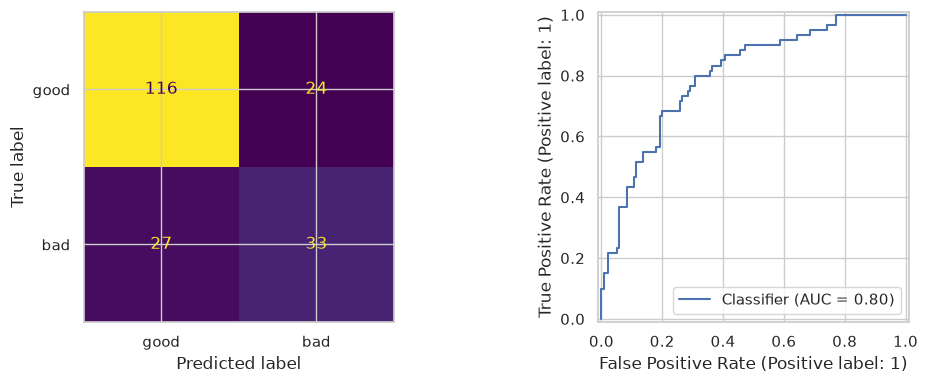

In [11]:
best_name = summary.iloc[0]["Model"]
best_params = results[best_name][0]
best = make_pipeline(best_name, best_params, prep).fit(X_train, y_train)

probabilities = best.predict_proba(X_test)[:, 1]
predictions = (probabilities >= 0.5).astype(int)

print("Selected by mean training-CV ROC-AUC:", best_name)
print("Selected hyperparameters:", best_params)
print("Holdout ROC-AUC:", round(roc_auc_score(y_test, probabilities), 3))
print("Holdout average precision:", round(average_precision_score(y_test, probabilities), 3))
print("Holdout balanced accuracy:", round(balanced_accuracy_score(y_test, predictions), 3))
print("Holdout Brier score:", round(brier_score_loss(y_test, probabilities), 3))
print(classification_report(
    y_test, predictions, target_names=["good", "bad"], zero_division=0
))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=["good", "bad"], ax=ax[0], colorbar=False
)
RocCurveDisplay.from_predictions(y_test, probabilities, ax=ax[1])
plt.tight_layout()
plt.show()

## Three most important original features
Estimate permutation importance on the held-out set using ROC-AUC as the score. To avoid confusing one-hot dummy columns with original variables, permutation is applied to raw input columns and the fitted pipeline re-encodes them. This is a predictive-importance ranking, not a causal explanation; correlated predictors can share or mask importance. Rank stability should be interpreted cautiously because the test set has only 200 applicants.

Top three predictive features:
1. checking_status: mean ROC-AUC decrease 0.1322 (SD 0.0346)
2. credit_amount: mean ROC-AUC decrease 0.0161 (SD 0.0072)
3. duration: mean ROC-AUC decrease 0.0155 (SD 0.0104)


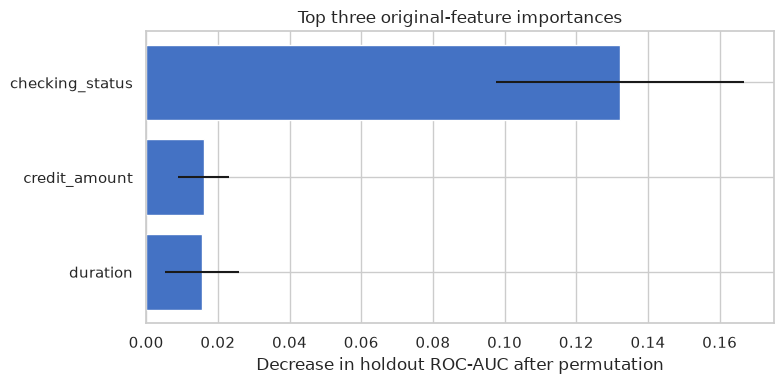

In [12]:
perm = permutation_importance(
    best, X_test, y_test, scoring="roc_auc",
    n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean AUC decrease": perm.importances_mean,
    "Std": perm.importances_std,
}).sort_values("Mean AUC decrease", ascending=False)

print("Top three predictive features:")
for i, r in enumerate(importance.head(3).itertuples(index=False), 1):
    print(f"{i}. {r.Feature}: mean ROC-AUC decrease {r[1]:.4f} (SD {r.Std:.4f})")

importance.head(10)

top3 = importance.head(3).sort_values("Mean AUC decrease")
plt.figure(figsize=(8, 4))
plt.barh(top3["Feature"], top3["Mean AUC decrease"], xerr=top3["Std"], color="#4472C4")
plt.yticks(range(len(top3)), [textwrap.fill(v, 18) for v in top3["Feature"]])
plt.xlabel("Decrease in holdout ROC-AUC after permutation")
plt.title("Top three original-feature importances")
plt.tight_layout()
plt.show()

## Robustness, fairness, calibration, and input validation

This section addresses uncertainty in the small holdout, compares the model families over repeated stratified folds, checks the effect of class weighting, measures feature-rank stability, audits age-group false positives, and adds a strict prediction-time validation layer. These are diagnostics on this historical dataset—not evidence of causal effects or a lending policy recommendation.



In [13]:
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

# 1) Holdout AUC uncertainty: stratified bootstrap preserves the observed class counts.
rng = np.random.default_rng(RANDOM_STATE)
y_arr = y_test.to_numpy()
p_arr = np.asarray(probabilities)
bad_idx = np.flatnonzero(y_arr == 1)
good_idx = np.flatnonzero(y_arr == 0)
boot_auc = []
for _ in range(3000):
    sampled = np.concatenate([
        rng.choice(good_idx, size=len(good_idx), replace=True),
        rng.choice(bad_idx, size=len(bad_idx), replace=True),
    ])
    boot_auc.append(roc_auc_score(y_arr[sampled], p_arr[sampled]))
auc_low, auc_high = np.quantile(boot_auc, [0.025, 0.975])
print(f"Holdout AUC: {roc_auc_score(y_test, probabilities):.3f}")
print(f"Stratified bootstrap 95% interval: {auc_low:.3f}–{auc_high:.3f}")
print(f"Holdout defaulters: {int(y_test.sum())} of {len(y_test)}")

# 2) Paired repeated-CV comparison on all 1,000 rows.
# Reuse the selected hyperparameters for each family; the test split is not used here.
forest_params = results["Random forest"][0]
logistic_params = results["Logistic regression"][0]
repeat_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
fold_auc = {}
for family, params in [("Random forest", forest_params), ("Logistic regression", logistic_params)]:
    scores = cross_val_score(
        make_pipeline(family, params, prep), X, y,
        cv=repeat_cv, scoring="roc_auc", n_jobs=1
    )
    fold_auc[family] = scores
paired_gap = fold_auc["Random forest"] - fold_auc["Logistic regression"]
paired_test = ttest_rel(fold_auc["Random forest"], fold_auc["Logistic regression"])
print("\\nRepeated 5x5 CV ROC-AUC")
for family, scores in fold_auc.items():
    print(f"{family}: mean={scores.mean():.3f}, SD={scores.std(ddof=1):.3f}")
print(f"Forest - logistic paired mean gap: {paired_gap.mean():.3f}")
print(f"Paired t-test (descriptive) p-value: {paired_test.pvalue:.3f}")
print(f"Paired t-style 95% interval for gap: "
      f"{paired_gap.mean() - 1.96*paired_gap.std(ddof=1)/np.sqrt(len(paired_gap)):.3f} to "
      f"{paired_gap.mean() + 1.96*paired_gap.std(ddof=1)/np.sqrt(len(paired_gap)):.3f}")
print("Note: repeated folds are dependent; this interval is descriptive, not a formal independent-sample test.")

# 3) Class weighting: compare the selected estimator with and without balanced weights.
# AUC measures ranking; mean predicted probability exposes calibration/base-rate shifts.
unweighted_params = dict(best_params)
balanced_params = dict(best_params)
unweighted_params["class_weight"] = None
balanced_params["class_weight"] = "balanced"
if best_name == "Random forest" and balanced_params.get("class_weight") not in [None, "balanced"]:
    balanced_params["class_weight"] = "balanced"
unweighted_model = make_pipeline(best_name, unweighted_params, prep).fit(X_train, y_train)
balanced_model = make_pipeline(best_name, balanced_params, prep).fit(X_train, y_train)
for label, fitted in [("No class weights", unweighted_model), ("Balanced weights", balanced_model)]:
    p = fitted.predict_proba(X_test)[:, 1]
    print(f"{label}: holdout AUC={roc_auc_score(y_test, p):.3f}; "
          f"mean predicted P(bad)={p.mean():.3f}; observed bad rate={y_test.mean():.3f}")

# 4) Top-three permutation feature stability across the five outer training folds.
fold_top_features = []
fold_importance_rows = []
for fold_no, (tr_idx, va_idx) in enumerate(
    StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X, y), 1
):
    fold_model = make_pipeline(best_name, best_params, prep).fit(X.iloc[tr_idx], y.iloc[tr_idx])
    fold_perm = permutation_importance(
        fold_model, X.iloc[va_idx], y.iloc[va_idx],
        scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE + fold_no, n_jobs=-1
    )
    order = np.argsort(fold_perm.importances_mean)[::-1]
    top_names = X.columns[order[:3]].tolist()
    fold_top_features.append(top_names)
    fold_importance_rows.extend(
        {"Fold": fold_no, "Rank": rank, "Feature": X.columns[idx],
         "Mean AUC decrease": fold_perm.importances_mean[idx]}
        for rank, idx in enumerate(order[:3], 1)
    )
fold_top_df = pd.DataFrame(fold_importance_rows)
print("\\nTop-three raw features by fold:")
print(fold_top_df.pivot(index="Fold", columns="Rank", values="Feature").to_string())
print("Top-three frequency:")
print(fold_top_df["Feature"].value_counts().head(6).to_string())

# 5) Fairness diagnostic: false-positive rate among actually-good applicants.
# A false positive here means a good applicant receives a predicted-bad flag at threshold 0.5.
audit = X_test[["age"]].copy()
audit["actual_good"] = (y_test == 0).to_numpy()
audit["predicted_bad"] = (predictions == 1)
audit["age_group"] = np.select(
    [audit["age"] < 25, audit["age"] > 40],
    ["Under 25", "Over 40"], default="25–40"
)
fairness_rows = []
for group in ["Under 25", "Over 40"]:
    subset = audit[(audit["age_group"] == group) & audit["actual_good"]]
    fpr = subset["predicted_bad"].mean() if len(subset) else np.nan
    fairness_rows.append({"Age group": group, "Good applicants": len(subset),
                          "False positives": int(subset["predicted_bad"].sum()),
                          "False-positive rate": fpr})
fairness_table = pd.DataFrame(fairness_rows)
print("\\nFalse-positive rates among good applicants (threshold=0.5):")
print(fairness_table.to_string(index=False, formatters={"False-positive rate": "{:.1%}".format}))

# Proxy diagnostic: can the remaining applicant fields predict whether an applicant is under 25?
# This directly tests whether age-related group membership is recoverable from other fields.
age_target = (X["age"] < 25).astype(int)
X_without_age = X.drop(columns="age")
age_proxy_model = Pipeline([
    ("prep", prep.__class__(transformers=[
        ("numeric", num_pipe, [c for c in num_cols if c != "age"]),
        ("categorical", cat_pipe, cat_cols),
    ])),
    ("model", RandomForestClassifier(
            n_estimators=300, min_samples_leaf=3, class_weight="balanced",
            random_state=RANDOM_STATE, n_jobs=-1
        ))
])
age_proxy_scores = cross_val_score(
    age_proxy_model, X_without_age, age_target,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="roc_auc", n_jobs=1
)
print(f"Under-25 proxy AUC from other fields: {age_proxy_scores.mean():.3f} "
      f"(fold SD {age_proxy_scores.std(ddof=1):.3f})")

# 6) Prediction-time validation. Unknown categories and impossible numeric values
# are rejected before the fitted pipeline can silently score them.
EXPECTED_COLUMNS = X.columns.tolist()
CATEGORY_LEVELS = {col: set(df[col].dropna().astype(str).unique()) for col in cat_cols}
NUMERIC_BOUNDS = {
    "duration": (1, 120),
    "credit_amount": (1, 1000000),
    "installment_commitment": (1, 4),
    "residence_since": (1, 4),
    "age": (18, 100),
    "existing_credits": (1, 10),
    "num_dependents": (1, 20),
}

def validate_applicants(applicants):
    """Return a cleaned copy or raise ValueError with row/field-level issues."""
    if isinstance(applicants, dict):
        applicants = pd.DataFrame([applicants])
    if not isinstance(applicants, pd.DataFrame):
        raise TypeError("Input must be a pandas DataFrame or a single-row dictionary.")
    issues = []
    missing_cols = sorted(set(EXPECTED_COLUMNS) - set(applicants.columns))
    extra_cols = sorted(set(applicants.columns) - set(EXPECTED_COLUMNS))
    if missing_cols:
        issues.append(f"Missing columns: {missing_cols}")
    if extra_cols:
        issues.append(f"Unexpected columns: {extra_cols}")
    if missing_cols or extra_cols:
        raise ValueError("Input schema invalid. " + "; ".join(issues))
    checked = applicants.loc[:, EXPECTED_COLUMNS].copy()
    for col in EXPECTED_COLUMNS:
        missing_rows = checked.index[checked[col].isna()].tolist()
        if missing_rows:
            issues.append(f"{col}: missing values at rows {missing_rows[:10]}")
    for col, (lower, upper) in NUMERIC_BOUNDS.items():
        values = pd.to_numeric(checked[col], errors="coerce")
        invalid = values.isna() | (values < lower) | (values > upper) | (values % 1 != 0)
        if invalid.any():
            rows = checked.index[invalid].tolist()[:10]
            issues.append(f"{col}: expected integer values in [{lower}, {upper}] at rows {rows}")
        checked[col] = values
    for col in cat_cols:
        values = checked[col].astype(str)
        unknown = sorted(set(values) - CATEGORY_LEVELS[col])
        if unknown:
            issues.append(f"{col}: unseen category values {unknown}")
        checked[col] = values
    if issues:
        raise ValueError("Applicant validation failed:\\n- " + "\\n- ".join(issues))
    return checked

# Demonstrate rejection of an impossible age and an unseen category.
invalid_example = X_test.iloc[[0]].copy()
invalid_example.loc[invalid_example.index[0], "age"] = 7
try:
    validate_applicants(invalid_example)
except ValueError as exc:
    print("\\nValidation correctly rejected an impossible age:")
    print(exc)

# Safe scoring wrapper: validation always runs before predict_proba.
def score_applicants(applicants, fitted_model=best):
    checked = validate_applicants(applicants)
    return fitted_model.predict_proba(checked)[:, 1]

print("\\nValidation layer ready: use score_applicants(new_applicant_rows) for guarded scoring.")


Holdout AUC: 0.801
Stratified bootstrap 95% interval: 0.730–0.864
Holdout defaulters: 60 of 200


\nRepeated 5x5 CV ROC-AUC
Random forest: mean=0.795, SD=0.029
Logistic regression: mean=0.787, SD=0.033
Forest - logistic paired mean gap: 0.008
Paired t-test (descriptive) p-value: 0.012
Paired t-style 95% interval for gap: 0.002 to 0.014
Note: repeated folds are dependent; this interval is descriptive, not a formal independent-sample test.


No class weights: holdout AUC=0.806; mean predicted P(bad)=0.309; observed bad rate=0.300
Balanced weights: holdout AUC=0.799; mean predicted P(bad)=0.428; observed bad rate=0.300


\nTop-three raw features by fold:
Rank                1               2                    3
Fold                                                      
1     checking_status        duration       savings_status
2     checking_status  credit_history             duration
3     checking_status  savings_status  other_payment_plans
4     checking_status        duration        credit_amount
5     checking_status  savings_status             duration
Top-three frequency:
Feature
checking_status        5
duration               4
savings_status         3
credit_history         1
other_payment_plans    1
credit_amount          1
\nFalse-positive rates among good applicants (threshold=0.5):
Age group  Good applicants  False positives False-positive rate
 Under 25               20                7               35.0%
  Over 40               51                8               15.7%


Under-25 proxy AUC from other fields: 0.807 (fold SD 0.024)
\nValidation correctly rejected an impossible age:
Applicant validation failed:\n- age: expected integer values in [18, 100] at rows [30]
\nValidation layer ready: use score_applicants(new_applicant_rows) for guarded scoring.


## SHAP analysis
SHAP (SHapley Additive exPlanations) attributes the model’s prediction to individual features using cooperative-game values. For the selected random forest we use `TreeExplainer` on the **preprocessed** feature space (scaled numerics + one-hot categories), which matches how the trees were trained.

We report:
- Global importance via mean absolute SHAP for the positive class (`bad`)
- A beeswarm summary of local effects
- A dependence view for the strongest transformed feature
- One example waterfall explanation

SHAP complements permutation importance: permutation measures drop in holdout ROC-AUC when a raw column is shuffled; SHAP decomposes each score into additive contributions on the encoded features. One-hot columns from the same original field can share importance.

### Understanding SHAP values in credit scoring

SHAP (SHapley Additive exPlanations) explains **why** a credit model scored an applicant the way it did. It answers: *how much did each feature push this prediction toward “bad” or “good” relative to a typical applicant?*

#### Core idea

SHAP borrows from cooperative game theory. Treat the model prediction as a “payout” and the features as “players.” Each feature’s SHAP value is its fair share of the difference between:

- the model’s **baseline** prediction (average over the data, or a chosen background), and
- the **actual** prediction for this applicant.

For an applicant i:

Prediction for applicant i = base value + the sum of that applicant’s feature contributions.

- φ₀: base value (expected model output)
- φᵢ,ⱼ: SHAP for feature j on applicant i
- Positive φ: pushes toward higher risk (e.g. higher P(bad))
- Negative φ: pushes toward lower risk

The contributions **add up** exactly to the prediction, which is useful for audit and communication.

#### Why this matters in credit scoring

Credit models are often used under regulatory and fairness scrutiny (e.g. adverse-action reasons, model risk management). Stakeholders need more than “score = 0.72”:

| Need | What SHAP provides |
|------|---------------------|
| **Instance explanation** | Why *this* application was declined or approved |
| **Global drivers** | Which variables matter on average (mean \|SHAP\|) |
| **Direction** | Whether high duration raises or lowers risk *in the model* |
| **Consistency** | Same feature contribution logic across applicants |

Unlike simple coefficient signs in a linear model, SHAP works for **nonlinear** models (random forests, gradient boosting, neural nets) and respects interactions in a principled way.

#### Global vs local

**Local (one applicant)**  
A waterfall or force plot shows, for one person, which factors raised risk (e.g. short checking history, long loan term) and which lowered it (e.g. solid credit history, higher savings). That supports adverse-action style narratives: “primary factors were …”

**Global (portfolio)**  
Averaging |φ_j| across applicants ranks features by overall impact. In this notebook, encoded levels of `checking_status`, plus `duration` and `credit_amount`, tend to dominate—aligned with permutation importance on the raw columns.

#### SHAP vs permutation importance

| | **Permutation importance** | **SHAP** |
|--|----------------------------|----------|
| Question | If I scramble this input, how much does **AUC** (or another metric) drop? | How much does this feature contribute to **this score**? |
| Level | Usually original columns | Often model’s internal features (e.g. one-hot levels) |
| Sign / direction | No (only magnitude of metric drop) | Yes (signed contribution) |
| Use in credit | Feature selection, monitoring stability | Explanations, challenge process, debugging |

They complement each other: permutation is about **predictive usefulness**; SHAP is about **additive attribution of the score**.

#### Practical caveats in lending

1. **Not causality** — SHAP explains the *model*, not the true data-generating process. A high SHAP on “no checking account” means the model relies on that pattern; it does not prove that opening an account would change default risk.

2. **Encoded vs raw features** — Tree SHAP on a pipeline with one-hot encoding attributes to levels like `checking_status_<0`, not the single field `checking_status`. For customer-facing reasons you often aggregate SHAP values back to the original variable.

3. **Correlation** — When features move together (income and employment length), credit can be split among them in ways that look unstable if you only look at one feature at a time.

4. **Base rate and threshold** — SHAP explains the model output (e.g. probability or margin), not the final accept/reject decision. Policy thresholds and cost weights still sit on top.

5. **Fairness** — SHAP can show reliance on sensitive or proxy features, but fairness needs explicit metrics and governance; SHAP alone does not certify compliance.

6. **Small / biased data** — On a dataset like German Credit (1,000 rows, historical), explanations are only as trustworthy as the model fit. Always pair with holdout metrics, calibration, and stability checks.

#### How to read the plots in this notebook

- **Beeswarm**: each point is one applicant; color = feature value; x-axis = SHAP. A red cloud on the right for long `duration` means “long term → higher predicted risk.”
- **Bar (mean \|SHAP\|)**: global ranking of drivers.
- **Waterfall**: for one applicant, ordered steps from base rate to final score.
- **Dependence**: how SHAP for feature j changes as j’s value changes (and optionally a color for an interaction feature).

**Bottom line:** In credit scoring, SHAP turns a black-box probability into an **additive, instance-level story** that is consistent with the model’s mathematics. Use it for explanation and diagnosis; use holdout performance, calibration, and policy rules for decisions; and never treat SHAP values as proof of real-world cause and effect.

### How SHAP values are calculated for tree models (TreeSHAP)

Exact Shapley values average a feature’s marginal contribution over every possible subset of the other features. For feature j, its SHAP value is the weighted average change in prediction when j is added to each subset; the weights ensure every feature ordering is treated fairly.

With M features, there are 2^(M-1) subsets for each feature, which is intractable for large M. **TreeSHAP** (Lundberg et al.) computes the same Shapley values for tree ensembles in polynomial time by exploiting the tree structure instead of enumerating coalitions.

#### Algorithmic idea

1. **Path decomposition** — Each tree maps an instance to a leaf by a sequence of yes/no splits. The prediction is the leaf value (or class probability estimate).
2. **Missing features as weighted branches** — When a feature in a subset is absent, TreeSHAP sends the instance down both children of a split on that feature, weighting each branch by the fraction of training mass that flows that way (cover).
3. **Dynamic programming on the path** — TreeSHAP tracks how much contribution belongs to features already fixed versus still free, avoiding explicit enumeration of all subsets.
4. **Ensemble** — For a forest, the prediction and each feature’s SHAP contribution are averaged across the trees.

#### Properties that matter in practice

| Property | Implication |
|----------|-------------|
| **Local accuracy** | Base value plus all feature contributions equals the explained model output |
| **Consistency** | If a feature’s marginal contribution never decreases, its SHAP value does not decrease |
| **Speed** | Polynomial in tree depth / nodes; feasible for the encoded design matrix in this notebook |
| **Feature space** | TreeSHAP explains the model as trained. After one-hot encoding, each dummy is a separate feature |

In this notebook, `shap.TreeExplainer(rf_model)` runs TreeSHAP on the random forest after the `ColumnTransformer` has scaled numerics and one-hot-encoded categoricals. The base value is the expected model output for class `bad`.

#### Path-dependent vs interventional

TreeSHAP has different conditioning modes, including path-dependent and interventional with an explicit background dataset. They differ in how correlated features are treated when a coordinate is absent. Both explain the fitted model; neither establishes a causal effect in the real world.


### How to aggregate SHAP values for categorical features

#### The problem

Pipelines typically expand each categorical column into several binary dummies. TreeSHAP then returns one value per dummy, e.g.:

- `categorical__checking_status_<0`
- `categorical__checking_status_0<=X<200`
- `categorical__checking_status_>=200`
- `categorical__checking_status_no checking`

Business users and adverse-action processes usually want **one** contribution for `checking_status`, not four. Aggregation restores the original-field view while preserving the additive identity.

#### Local aggregation (per applicant)

For one applicant and one original categorical field, add the SHAP contributions for every encoded column belonging to that field. The grouped contribution plus the base value and all other feature contributions still equals the model output.

The signed grouped contribution indicates whether that categorical field pushes the applicant’s score toward higher or lower predicted probability of `bad`.

#### Global importance of an original field

A useful original-field importance score is the average, across applicants, of the absolute value of the field’s summed SHAP contribution. This ranks the impact of the original field rather than its individual dummy levels.

An alternative is to sum each dummy’s mean absolute SHAP value. That can overstate importance when levels compete, so this notebook uses the absolute value after aggregation when ranking original columns.

Numeric features (duration, credit amount, age, …) remain single columns; their SHAP contribution does not need grouping.

#### Mapping encoded names → original fields

In scikit-learn, `get_feature_names_out()` yields names like `numeric__duration` and `categorical__purpose_radio/tv`. The code below maps each encoded column to its original name using the known raw column list, sums SHAP columns within each group, and ranks original features by mean absolute aggregated contribution.

#### Caveats

| Caveat | Detail |
|--------|--------|
| **Reference level** | If one dummy is dropped (`drop='first'`), part of that level’s effect sits in the base value; summing remaining dummies is still standard practice but is not identical to a native-categorical explainer |
| **Only group true levels** | Sum only dummies of the same original field—never pool unrelated categoricals |
| **Correlation** | Aggregation improves reporting clarity; it does not remove correlation among different original fields |
| **Match permutation view** | Permutation importance shuffles raw columns; aggregated SHAP is the analogous one-number-per-original-field attribution view |


In [14]:
import shap

# Transform holdout through the fitted preprocessor (same space the trees see)
X_test_t = best.named_steps["prep"].transform(X_test)
if hasattr(X_test_t, "toarray"):
    X_test_t = X_test_t.toarray()
feature_names = list(best.named_steps["prep"].get_feature_names_out())
rf_model = best.named_steps["model"]

explainer = shap.TreeExplainer(rf_model)
shap_raw = explainer.shap_values(X_test_t)

# Normalize to positive-class (bad) SHAP matrix of shape (n_samples, n_features)
if isinstance(shap_raw, list):
    shap_pos = shap_raw[1]
elif getattr(shap_raw, "ndim", 0) == 3:
    # (n_samples, n_features, n_classes)
    shap_pos = shap_raw[:, :, 1]
else:
    shap_pos = shap_raw

expected_value = explainer.expected_value
if isinstance(expected_value, (list, tuple, np.ndarray)):
    base_value = float(np.asarray(expected_value).ravel()[-1])
else:
    base_value = float(expected_value)

print("SHAP matrix shape (positive class):", np.asarray(shap_pos).shape)
print("Number of encoded features:", len(feature_names))
print("Base value (expected model output for class bad):", round(base_value, 4))

mean_abs = np.abs(shap_pos).mean(axis=0)
shap_importance = (
    pd.DataFrame({"Feature": feature_names, "mean_|SHAP|": mean_abs})
    .sort_values("mean_|SHAP|", ascending=False)
)
print("\nTop 15 encoded features by mean |SHAP|:")
print(shap_importance.head(15).to_string(index=False))

SHAP matrix shape (positive class): (200, 61)
Number of encoded features: 61
Base value (expected model output for class bad): 0.5

Top 15 encoded features by mean |SHAP|:
                                                   Feature  mean_|SHAP|
                  categorical__checking_status_no checking     0.070848
                           categorical__checking_status_<0     0.045946
                                         numeric__duration     0.037978
categorical__credit_history_critical/other existing credit     0.027278
                          categorical__savings_status_<100     0.027180
                                    numeric__credit_amount     0.023063
                                              numeric__age     0.015844
                                categorical__employment_<1     0.015627
                           numeric__installment_commitment     0.014480
               categorical__property_magnitude_real estate     0.014429
                     categorical__ch

Aggregated SHAP shape (rows x original features): (200, 20)

Original features ranked by mean |aggregated SHAP|:
               Feature  mean_|aggregated_SHAP|
       checking_status                0.102447
        savings_status                0.038103
              duration                0.037978
        credit_history                0.027846
   other_payment_plans                0.024977
         credit_amount                0.023063
    property_magnitude                0.021255
            employment                0.020762
               purpose                0.019913
       personal_status                0.018186
               housing                0.017824
                   age                0.015844
installment_commitment                0.014480
         own_telephone                0.010027
                   job                0.007515
         other_parties                0.004923
       residence_since                0.003970
        foreign_worker                0.0

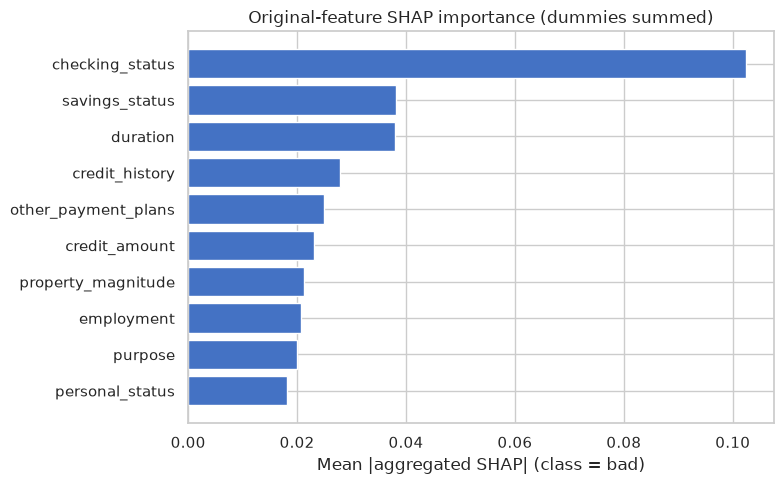

In [15]:
# Aggregate SHAP values from encoded columns back to original feature names
import re

encoded = list(feature_names)
shap_mat = np.asarray(shap_pos)  # (n_samples, n_encoded)

# Map each encoded name -> original column using known raw feature names
raw_features = list(X_test.columns)
orig_of = []
for name in encoded:
    # sklearn style: "numeric__duration" or "categorical__checking_status_<0"
    if name.startswith("numeric__"):
        orig_of.append(name.replace("numeric__", "", 1))
    elif name.startswith("categorical__"):
        rest = name.replace("categorical__", "", 1)
        matched = None
        # Longest raw categorical name that is a prefix of "rest"
        for col in sorted(raw_features, key=len, reverse=True):
            if rest == col or rest.startswith(col + "_"):
                matched = col
                break
        orig_of.append(matched if matched is not None else rest)
    else:
        orig_of.append(name)

orig_of = np.asarray(orig_of)
assert len(orig_of) == shap_mat.shape[1]

# Local aggregated SHAP: one column per original feature
aggregated = {}
for col in raw_features:
    idx = np.where(orig_of == col)[0]
    aggregated[col] = shap_mat[:, idx].sum(axis=1)

agg_shap_df = pd.DataFrame(aggregated, index=X_test.index)
print("Aggregated SHAP shape (rows x original features):", agg_shap_df.shape)

# Global importance of original features (mean |aggregated SHAP|)
agg_importance = (
    pd.DataFrame({
        "Feature": agg_shap_df.columns,
        "mean_|aggregated_SHAP|": np.abs(agg_shap_df).mean(axis=0).values,
    })
    .sort_values("mean_|aggregated_SHAP|", ascending=False)
)
print("\nOriginal features ranked by mean |aggregated SHAP|:")
print(agg_importance.to_string(index=False))

# Sanity check: row-wise sum of aggregated SHAP + base ≈ model output margin/proba scale
# (TreeSHAP for predict_proba class-1 explains the class probability contribution structure)
row_sum = agg_shap_df.sum(axis=1) + base_value
print("\nMean |base + sum(agg SHAP) - P(bad)|:", round(np.mean(np.abs(row_sum.values - probabilities)), 6))

# Bar chart comparable to permutation importance (original-feature level)
top_n = agg_importance.head(10).sort_values("mean_|aggregated_SHAP|")
plt.figure(figsize=(8, 5))
plt.barh(top_n["Feature"], top_n["mean_|aggregated_SHAP|"], color="#4472C4")
plt.xlabel("Mean |aggregated SHAP| (class = bad)")
plt.title("Original-feature SHAP importance (dummies summed)")
plt.tight_layout()
plt.show()

### Reading the SHAP summary plots (full guide)

The next code cell draws two global views of local SHAP values on the **encoded** feature space (scaled numerics + one-hot categoricals) for class `bad`. The matrix has one row per holdout applicant and one column per model feature.

#### 1. Beeswarm summary plot

**What each element means**

| Visual element | Meaning |
|----------------|---------|
| **One row** | One encoded feature (e.g. `numeric__duration`, `categorical__checking_status_<0`) |
| **One dot** | One applicant’s SHAP value for that feature |
| **Horizontal position** | Signed contribution to P(bad): right = increases risk, left = decreases risk |
| **Color** | Feature value for that applicant (typical scale: blue = low, red = high) |
| **Vertical stacking** | Density of applicants with similar SHAP values; thick regions = many people share that contribution |
| **Row order** | Features sorted by global impact, usually mean absolute SHAP value descending |

**How to interpret patterns**

- **Red dots on the right** for `duration`: long loans push predicted risk **up**.
- **Blue dots on the right** for the same feature would mean low values raise risk (less common for duration).
- **Narrow vertical strip near zero**: feature rarely moves the score much.
- **Wide horizontal spread**: feature sometimes helps and sometimes hurts a lot—strong but context-dependent effect.
- **One-hot rows** (e.g. `checking_status_no checking`): color is mostly 0/1. Red usually means “this level is active.” If active levels sit on the right, that category level is associated with higher model risk.

**Credit-specific reading**

Beeswarm answers: *When this feature is high or low, does the model move applicants toward default or toward good?* It does **not** prove causality.

#### 2. Bar plot of mean absolute SHAP

Encoded-feature importance is the average absolute SHAP contribution across applicants.

- Length of each bar = average **magnitude** of contribution (direction is discarded).
- Ranking = global “which encoded columns matter most on average.”
- Use this for a quick leaderboard; use the beeswarm when you need **sign** and **value dependence**.

#### 3. Encoded vs original features in these plots

These two plots are **dummy-level**. Several rows may belong to the same original field (`checking_status_*`). That is intentional for TreeSHAP: the model only sees encoded columns. For a single importance number per original variable, use the **aggregated SHAP** table and bar chart computed earlier.

#### 4. What “good” explanation hygiene looks like

1. Confirm local accuracy on a few rows: the base value plus the sum of feature contributions should approximately equal the model output.
2. Cross-check top beeswarm rows with permutation importance on raw columns.
3. Do not report a single dummy as “the” reason without mentioning the full categorical—or aggregate first.
4. Pair plots with holdout metrics; attractive SHAP charts do not validate discrimination or calibration.


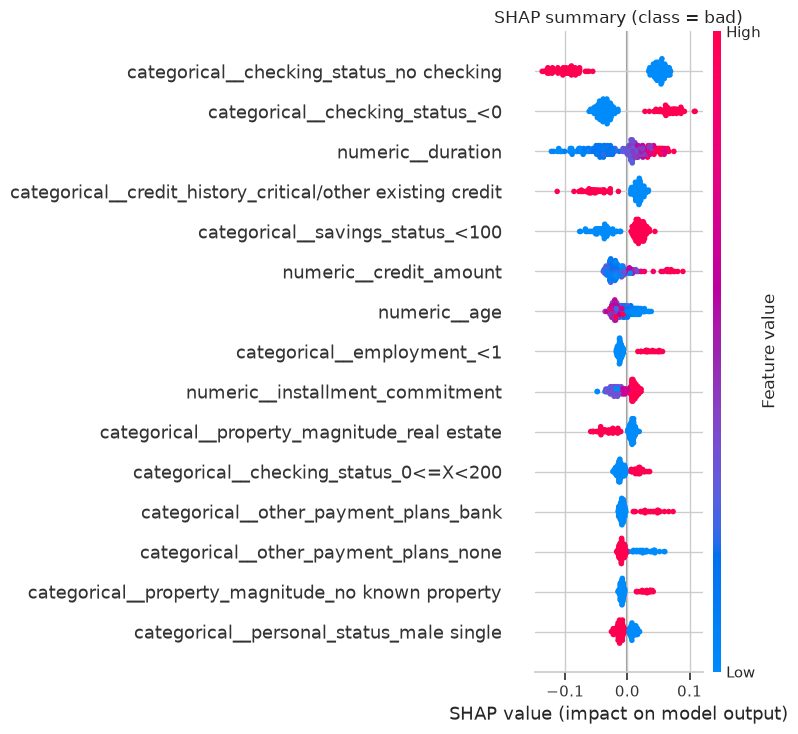

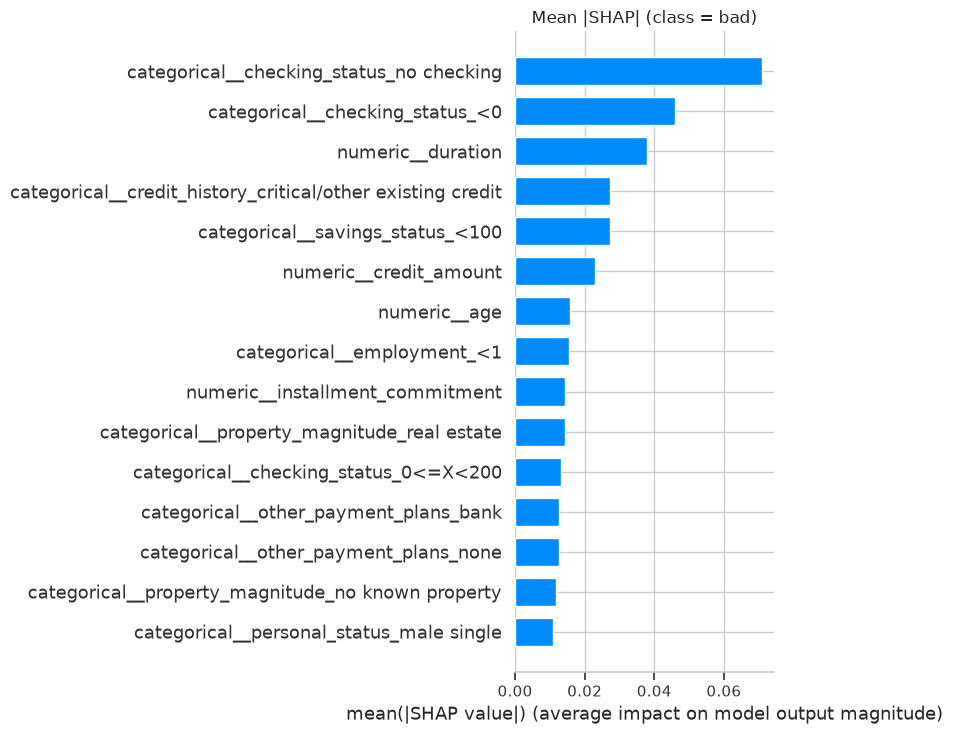

In [16]:
# Beeswarm summary for the positive class
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_pos,
    X_test_t,
    feature_names=feature_names,
    max_display=15,
    show=False,
)
plt.title("SHAP summary (class = bad)")
plt.tight_layout()
plt.show()

# Bar plot of global mean |SHAP|
plt.figure(figsize=(10, 6))
shap.summary_plot(
    shap_pos,
    X_test_t,
    feature_names=feature_names,
    plot_type="bar",
    max_display=15,
    show=False,
)
plt.title("Mean |SHAP| (class = bad)")
plt.tight_layout()
plt.show()

### Reading the SHAP dependence plot

A **dependence plot** shows, for one feature j, how the SHAP value φⱼ changes as the feature value changes across applicants.

| Axis / element | Meaning |
|----------------|---------|
| **x-axis** | Raw value of feature j in the *model matrix* (scaled numeric, or 0/1 for a dummy) |
| **y-axis** | SHAP value φⱼ(xᵢ) for class `bad` |
| **Each point** | One holdout applicant |
| **Optional color** | Value of a second feature (interaction partner) chosen automatically or manually |

**How to read it**

- An upward slope: higher feature values → larger positive contribution to risk.
- A flat band near zero: little marginal effect in the region plotted.
- Vertical scatter at the same x: interaction or path-dependence—the same feature value contributes differently depending on other features.
- For a **binary dummy**, you mainly see two vertical strips at 0 and 1; compare typical φ when the level is off vs on.

The cell below plots dependence for the strongest encoded feature by mean |SHAP|. For continuous fields such as `numeric__duration` or `numeric__credit_amount`, the shape is often more informative than for a single dummy.

Dependence feature: categorical__checking_status_no checking


<Figure size 800x500 with 0 Axes>

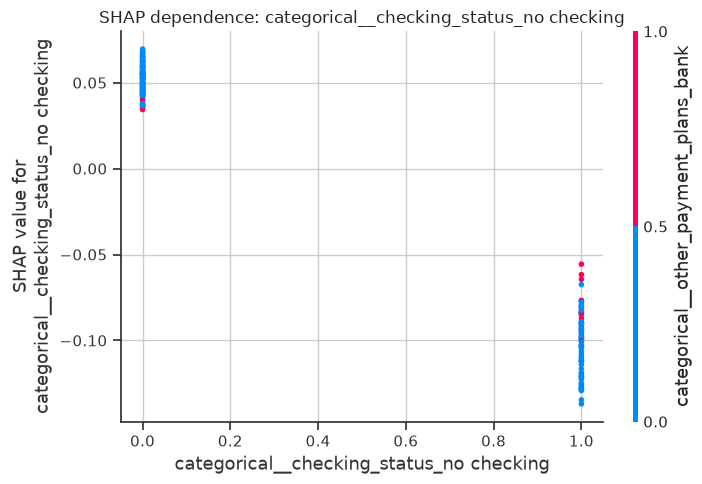

In [17]:
# Dependence plot for the strongest encoded feature
top_feat = shap_importance.iloc[0]["Feature"]
top_idx = feature_names.index(top_feat)
print("Dependence feature:", top_feat)

plt.figure(figsize=(8, 5))
shap.dependence_plot(
    top_idx,
    shap_pos,
    X_test_t,
    feature_names=feature_names,
    show=False,
)
plt.title(f"SHAP dependence: {top_feat}")
plt.tight_layout()
plt.show()

### Reading SHAP waterfall plots (local explanations)

A **waterfall** explains **one** applicant. It starts at the base value φ₀ (expected model output) and adds feature contributions one at a time until the final prediction f(xᵢ).

| Element | Meaning |
|---------|---------|
| **Base value** | Average model output over the background (here, expected contribution toward class `bad`) |
| **Red bars** | Features that **increase** predicted risk for this person |
| **Blue bars** | Features that **decrease** predicted risk |
| **Bar length** | |φⱼ(xᵢ)| — strength of that feature’s push |
| **Order** | Typically largest impact first (or plot default order) |
| **Final value** | Model output for this applicant (probability / margin scale used by the explainer) |

**Credit-use pattern**

1. Pick a high-risk and a low-risk case (as in the next cell).
2. List the largest red bars as model-driven risk factors for that file.
3. List the largest blue bars as offsetting factors.
4. If the categorical was one-hot encoded, several small bars may be levels of the same field—sum them mentally or use aggregated SHAP for cleaner narrative.

Waterfalls are the right tool for **case-level** review and challenge; beeswarm/bar plots remain the right tool for **portfolio-level** drivers.

Highest predicted risk row=195, P(bad)=0.800, true=1


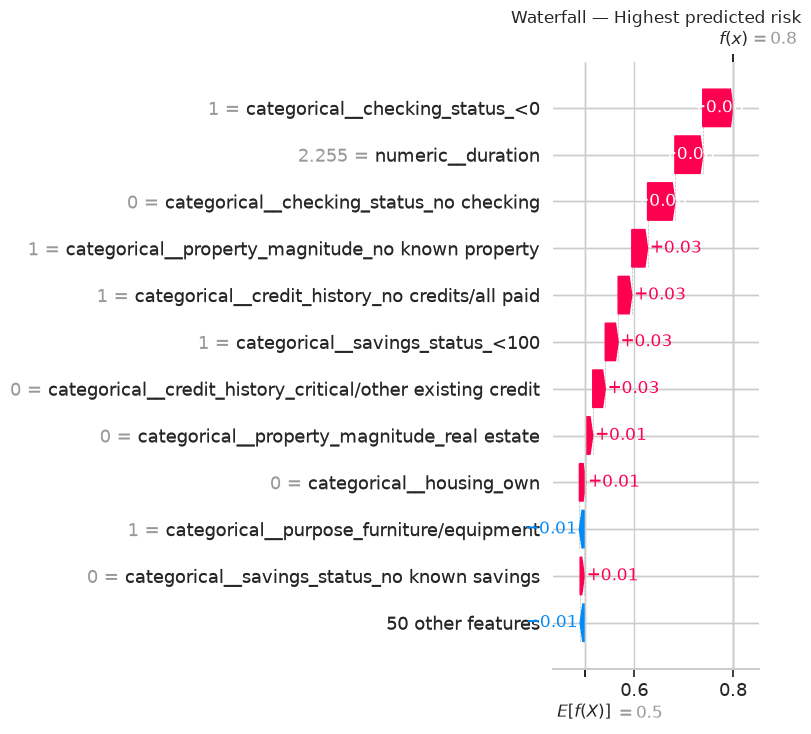

Lowest predicted risk row=12, P(bad)=0.046, true=0


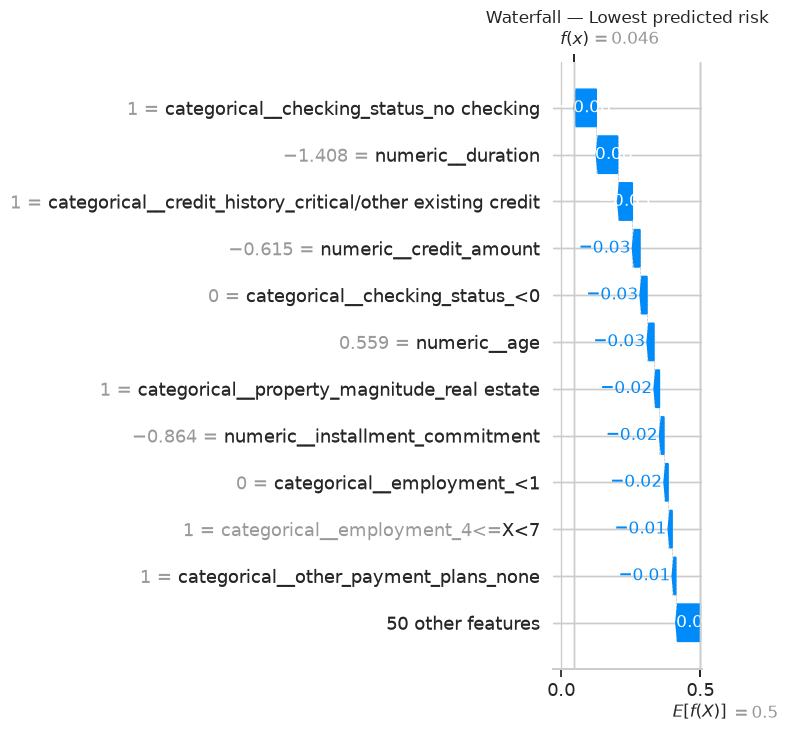

In [18]:
# Local explanation for one high-risk and one low-risk applicant
proba_test = probabilities
high_idx = int(np.argmax(proba_test))
low_idx = int(np.argmin(proba_test))

def show_waterfall(i, label):
    explanation = shap.Explanation(
        values=np.asarray(shap_pos[i]),
        base_values=base_value,
        data=np.asarray(X_test_t[i]),
        feature_names=feature_names,
    )
    print(f"{label} row={i}, P(bad)={proba_test[i]:.3f}, true={int(y_test.iloc[i])}")
    plt.figure()
    shap.plots.waterfall(explanation, max_display=12, show=False)
    plt.title(f"Waterfall — {label}")
    plt.tight_layout()
    plt.show()

show_waterfall(high_idx, "Highest predicted risk")
show_waterfall(low_idx, "Lowest predicted risk")

### SHAP vs permutation importance
Permutation importance ranks **original** columns by how much holdout ROC-AUC falls when that column is shuffled. SHAP ranks **encoded** columns by average magnitude of local contributions to the score. Checking-status one-hot levels often dominate both views; duration and credit amount remain important numerically. Use both: permutation for decision-relevant raw fields, SHAP for direction and instance-level story.

## Interpretation and limitations

The notebook now reports uncertainty around the holdout ROC-AUC, repeated stratified-CV comparisons between logistic regression and random forest, the effect of class weighting on both ranking and average predicted risk, and feature-rank stability across folds. Treat repeated-fold comparisons as descriptive because folds overlap across repeats.

The fairness audit reports false-positive rates among applicants who are actually labelled good, split into under-25 and over-40 groups at the 0.5 classification threshold. The age-proxy diagnostic asks how well the remaining fields predict whether an applicant is at least 40. A high proxy AUC signals that dropping the age column alone may not remove age-related information; it does not establish unlawful discrimination or causality.

The validation layer checks the exact input schema, missing values, numeric plausibility bounds, integer-valued fields, and categorical values not observed in the training dataset. Use `score_applicants(...)` rather than calling `predict_proba` directly for new applicant records. The numeric bounds are operational guardrails for this dataset and should be reviewed against authoritative business rules before deployment.

The data are small, historical, and contain no time dimension; random-split validation estimates performance on another sample from the same source, not future-period or population-shift performance. Credit outcomes are imbalanced (70% good, 30% bad), so accuracy alone would be misleading. A production decision would require out-of-time validation, calibration and threshold/cost analysis, fairness review, monitoring, and documented governance. This exercise is educational and is **not** suitable for making real lending decisions.


## References
- Dataset: [Kaggle — Weka German Credit](https://www.kaggle.com/datasets/btolar1/weka-german-credit)
- Background supplied with the task: Tiziano Bellini, *IFRS 9 and CECL Credit Risk Modelling and Validation*, Chapter 2 (one-year PD, logistic/GLM models, model validation).
- Bayesian optimization: Gaussian-process surrogate with expected-improvement acquisition for sequential design of expensive black-box scores such as CV AUC.